In [9]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# -----------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_10_Data/F5_Week_10_inputs.npy')
y = np.load('..\Function_5_Data\Week_10_Data/F5_Week_10_outputs.npy')

n, d = X.shape
bounds = np.array([[0.0, 1.0]] * d)
dim_names = [f"x{i+1}" for i in range(d)]

Target distribution before/after transformation (n=29)
Raw y      : min=0.112940, max=8449.496898, mean=1185.350605, std=2136.434489, skew=2.098725
log(y)     : min=-2.180900, max=9.041862, mean=5.041960, std=2.484444, skew=-0.527397
Box-Cox fitted lambda = 0.069483 (lambda=0 is exactly the log transform - still close to 0)


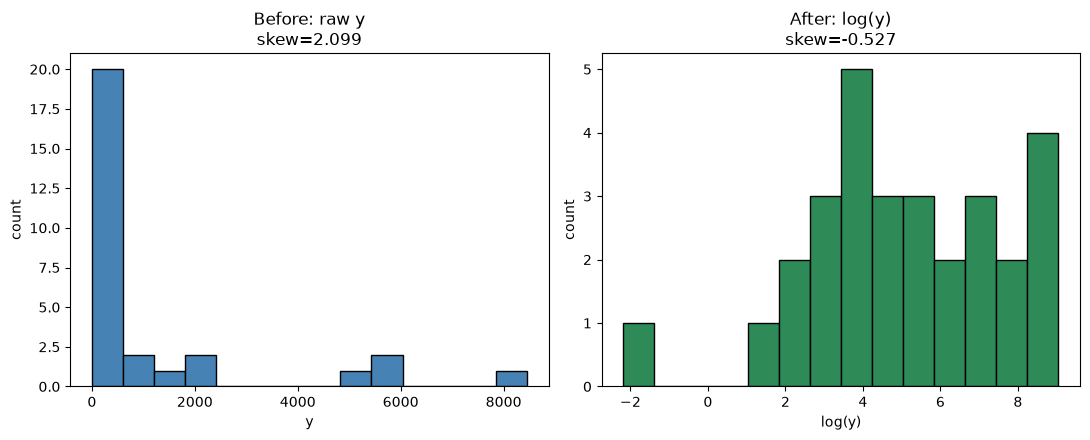

In [12]:
# =========================================================================
# 2. Target distribution before / after transformation
# =========================================================================
print("=" * 100)
print("Target distribution before/after transformation (n=%d)" % n)
print("=" * 100)
log_y = np.log(y)
print(f"Raw y      : min={y.min():.6f}, max={y.max():.6f}, "
      f"mean={y.mean():.6f}, std={y.std():.6f}, skew={stats.skew(y):.6f}")
print(f"log(y)     : min={log_y.min():.6f}, max={log_y.max():.6f}, "
      f"mean={log_y.mean():.6f}, std={log_y.std():.6f}, skew={stats.skew(log_y):.6f}")
bc_y, bc_lambda = stats.boxcox(y)
print(f"Box-Cox fitted lambda = {bc_lambda:.6f} "
      f"(lambda=0 is exactly the log transform - still close to 0)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(y, bins=14, color="steelblue", edgecolor="k")
axes[0].set_title(f"Before: raw y\nskew={stats.skew(y):.3f}")
axes[0].set_xlabel("y")
axes[0].set_ylabel("count")

axes[1].hist(log_y, bins=14, color="seagreen", edgecolor="k")
axes[1].set_title(f"After: log(y)\nskew={stats.skew(log_y):.3f}")
axes[1].set_xlabel("log(y)")
axes[1].set_ylabel("count")

plt.tight_layout()

In [ ]:
# =========================================================================
# 3. Surrogate: re-validate log(y) vs raw-y, isotropic vs ARD, with n=29
# =========================================================================
print("\n" + "=" * 100)
print("Surrogate re-validation (n=%d)" % n)
print("=" * 100)


def make_gp(ard: bool, n_restarts=20):
    ls = np.full(d, 1.0) if ard else 1.0
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=ls, length_scale_bounds=(1e-2, 1e2), nu=2.5)
        + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-8, 1e-1))
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        alpha=1e-10,
        n_restarts_optimizer=n_restarts,
        random_state=SEED,
    )


def loo_nlpd(target, ard, n_restarts=5):
    loo = LeaveOneOut()
    nlpds = []
    for train_idx, test_idx in loo.split(X):
        gp_i = make_gp(ard=ard, n_restarts=n_restarts)
        gp_i.fit(X[train_idx], target[train_idx])
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        sigma = max(sigma[0], 1e-6)
        nlpd = 0.5 * np.log(2 * np.pi * sigma ** 2) + \
            0.5 * ((target[test_idx][0] - mu[0]) ** 2) / (sigma ** 2)
        nlpds.append(nlpd)
    return np.mean(nlpds)


loo_log_iso = loo_nlpd(log_y, ard=False)
loo_log_ard = loo_nlpd(log_y, ard=True)
loo_raw_iso = loo_nlpd(y, ard=False)

print(f"log(y), isotropic LOO NLPD = {loo_log_iso:.6f}")
print(f"log(y), ARD       LOO NLPD = {loo_log_ard:.6f}")
print(f"raw y,  isotropic LOO NLPD = {loo_raw_iso:.6f}  (own units, not "
      f"directly comparable to the log-y rows - shown only as a trend check)")

chosen_ard = loo_log_ard < loo_log_iso
model_name = "ARD" if chosen_ard else "isotropic"
print(f"-> {model_name} has the lower LOO NLPD for log(y) with n={n}.")
print(f"Decision: log(y) target with {model_name} length-scale(s).")

gp = make_gp(ard=chosen_ard, n_restarts=30)
gp.fit(X, log_y)
ls_fitted = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
amp = gp.kernel_.k1.k1.constant_value
noise = gp.kernel_.k2.noise_level
print(f"\nFitted kernel: {gp.kernel_}")
if len(ls_fitted) == 1:
    print(f"length-scale (shared) = {ls_fitted[0]:.6f}")
else:
    print(f"length-scales = {dict(zip(dim_names, ls_fitted.round(6)))}")
print(f"amplitude^2 = {amp:.6f}, noise = {noise:.6e}")
for name, v in zip(dim_names if len(ls_fitted) > 1 else ["shared"], ls_fitted):
    if np.isclose(v, 1e-2, rtol=1e-3) or np.isclose(v, 1e2, rtol=1e-3):
        print(f"  WARNING: {name} length-scale ({v:.6f}) is on an optimisation bound.")


Surrogate re-validation (n=29)
log(y), isotropic LOO NLPD = 2.046220
log(y), ARD       LOO NLPD = 3.149626
raw y,  isotropic LOO NLPD = 7.290187  (own units, not directly comparable to the log-y rows - shown only as a trend check)
-> isotropic has the lower LOO NLPD for log(y) with n=29.
Decision: log(y) target with isotropic length-scale(s).

Fitted kernel: 1.1**2 * Matern(length_scale=0.486, nu=2.5) + WhiteKernel(noise_level=1e-08)
length-scale (shared) = 0.485944
amplitude^2 = 1.218879, noise = 1.000000e-08


In [ ]:
# =========================================================================
# 4. Acquisition: bias towards EXPLOITATION
# =========================================================================
print("=" * 100)
print("Acquisition function - re-tuned for exploitation")
print("=" * 100)
print("""
Three changes relative to previous round, all standard ways to shift EI/BO
towards exploitation when the evaluation budget is nearly spent:

  (a) xi lowered further: 0.002 -> 0.000100. 

  (b) acquisition optimisation is additionally run inside a trust region
      around the current incumbent (+/- 0.25 in each coordinate, clipped
      to [0,1]) rather than only the full unit hypercube.

  (c) a UCB acquisition with a SMALL kappa is computed alongside EI purely
      as a cross-check: UCB(x) = mu(x) + kappa*sigma(x), kappa=0.100000.
      Small kappa makes UCB almost pure exploitation of the posterior
      mean. If EI(xi->0) and UCB(small kappa) agree on the same region, 
      that is good evidence the recommendation is driven by the mean surface,
      not residual uncertainty-chasing.
""")

f_best = log_y.max()
xi = 0.0001
kappa = 0.1

TRUST_RADIUS = 0.25
incumbent_idx = np.argmax(y)
incumbent_x = X[incumbent_idx]
trust_bounds = np.stack([
    np.maximum(incumbent_x - TRUST_RADIUS, 0.0),
    np.minimum(incumbent_x + TRUST_RADIUS, 1.0),
], axis=1)


def expected_improvement(Xcand, gp, f_best, xi):
    Xcand = np.atleast_2d(Xcand)
    mu, sigma = gp.predict(Xcand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - f_best - xi
    Z = imp / sigma
    return imp * norm.cdf(Z) + sigma * norm.pdf(Z)


def ucb(Xcand, gp, kappa):
    Xcand = np.atleast_2d(Xcand)
    mu, sigma = gp.predict(Xcand, return_std=True)
    return mu + kappa * sigma


def neg_ei(x, gp, f_best, xi):
    return -expected_improvement(x.reshape(1, -1), gp, f_best, xi)[0]


def neg_ucb(x, gp, kappa):
    return -ucb(x.reshape(1, -1), gp, kappa)[0]


N_RESTARTS_ACQ = 300


def optimise_acq(neg_fn, args, search_bounds, seed=SEED):
    rng_local = np.random.default_rng(seed)
    starts = rng_local.uniform(search_bounds[:, 0], search_bounds[:, 1],
                                size=(N_RESTARTS_ACQ, d))
    vertices = np.array(np.meshgrid(*search_bounds)).reshape(d, -1).T
    inside = np.all((X >= search_bounds[:, 0]) & (X <= search_bounds[:, 1]), axis=1)
    starts = np.vstack([starts, vertices, X[inside]])
    best_x, best_val = None, np.inf
    for x0 in starts:
        res = minimize(neg_fn, x0, args=args, bounds=search_bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x
    return best_x, -best_val


def neg_mean(x, gp):
    return -gp.predict(x.reshape(1, -1))[0]

x_ei_global, val_ei_global = optimise_acq(neg_ei, (gp, f_best, xi), bounds)
x_ei_trust, val_ei_trust = optimise_acq(neg_ei, (gp, f_best, xi), trust_bounds)
x_ucb_trust, val_ucb_trust = optimise_acq(neg_ucb, (gp, kappa), trust_bounds)
x_mean_trust, val_mean_trust = optimise_acq(neg_mean, (gp,), trust_bounds)

print(f"Current incumbent               : x* = {incumbent_x}  "
      f"y* = {y.max():.6f}")
print(f"\nTrust region bounds (+/-{TRUST_RADIUS} around incumbent, clipped):")
for i in range(d):
    print(f"  {dim_names[i]}: [{trust_bounds[i,0]:.6f}, {trust_bounds[i,1]:.6f}]")

print(f"\n[Global search]  EI-argmax         x = {x_ei_global}  "
      f"EI = {val_ei_global:.6f}")
print(f"[Trust region]   EI-argmax         x = {x_ei_trust}  "
      f"EI = {val_ei_trust:.6f}")
print(f"[Trust region]   UCB-argmax        x = {x_ucb_trust}  "
      f"UCB = {val_ucb_trust:.6f}")
print(f"[Trust region]   posterior-mean-argmax (pure exploitation, no "
      f"uncertainty term at all)  x = {x_mean_trust}  "
      f"mean(log y) = {val_mean_trust:.6f}")

agree = np.linalg.norm(x_ei_trust - x_ucb_trust) < 0.1
print(f"\nEI(trust-region) and UCB(trust-region, small kappa) "
      f"{'AGREE' if agree else 'DISAGREE'} on the recommended region.")


# Recommended next point: trust-region UCB with small kappa.
best_x = x_ucb_trust
mu_new, sigma_new = gp.predict(best_x.reshape(1, -1), return_std=True)
mu_new, sigma_new = mu_new[0], sigma_new[0]

print("=" * 100)
print("Recommended round-5 query point (6 d.p.)")
print("=" * 100)
print(f"Acquisition used                 = UCB (trust-region, kappa={kappa})")
print(f"Proposed x                       = {np.array2string(best_x, precision=6, floatmode='fixed')}")
print(f"UCB value at proposed point      = {val_ucb_trust:.6f}")
print(f"GP posterior mean  (log-y)       = {mu_new:.6f}")
print(f"GP posterior std   (log-y)       = {sigma_new:.6f}")
median_pred = np.exp(mu_new)
mean_pred = np.exp(mu_new + 0.5 * sigma_new ** 2)
ci_lo = np.exp(mu_new - 1.645 * sigma_new)
ci_hi = np.exp(mu_new + 1.645 * sigma_new)
print(f"Predicted y (median = exp(mu))   = {median_pred:.6f}")
print(f"Predicted y (mean, log-normal)   = {mean_pred:.6f}")
print(f"90% CI for y                     = [{ci_lo:.6f}, {ci_hi:.6f}]")

Acquisition function - re-tuned for exploitation

Three changes relative to previous round, all standard ways to shift EI/BO
towards exploitation when the evaluation budget is nearly spent:

  (a) xi lowered further: 0.002 -> 0.000100. 

  (b) acquisition optimisation is additionally run inside a trust region
      around the current incumbent (+/- 0.25 in each coordinate, clipped
      to [0,1]) rather than only the full unit hypercube.

  (c) a UCB acquisition with a SMALL kappa is computed alongside EI purely
      as a cross-check: UCB(x) = mu(x) + kappa*sigma(x), kappa=0.100000.
      Small kappa makes UCB almost pure exploitation of the posterior
      mean. If EI(xi->0) and UCB(small kappa) agree on the same region, 
      that is good evidence the recommendation is driven by the mean surface,
      not residual uncertainty-chasing.

Current incumbent               : x* = [0.988753 1.       1.       1.      ]  y* = 8449.496898

Trust region bounds (+/-0.25 around incumbent, clip

In [15]:
# =========================================================================
# The domain vertex nearest the incumbent, as an explicit candidate
# =========================================================================

print("=" * 100)
print("Nearest-vertex candidate vs the model's proposal")
print("=" * 100)
vertex = np.round(incumbent_x)
already = np.any(np.all(np.isclose(X, vertex, atol=1e-6), axis=1))
mu_v, sigma_v = gp.predict(vertex.reshape(1, -1), return_std=True)
mu_v, sigma_v = mu_v[0], sigma_v[0]
print(f"Vertex nearest the incumbent     = {np.array2string(vertex, precision=6, floatmode='fixed')}"
      f"  ({'already evaluated' if already else 'NOT yet evaluated'})")
print(f"  posterior mean/std (log-y)     = {mu_v:.6f} / {sigma_v:.6f}")
print(f"  predicted y (median)           = {np.exp(mu_v):.6f}   "
      f"90% CI [{np.exp(mu_v - 1.645 * sigma_v):.6f}, {np.exp(mu_v + 1.645 * sigma_v):.6f}]")
print(f"  EI = {expected_improvement(vertex, gp, f_best, xi)[0]:.6f}   "
      f"UCB = {ucb(vertex, gp, kappa)[0]:.6f}")
print(f"Model proposal (UCB, trust)      = {np.array2string(best_x, precision=6, floatmode='fixed')}"
      f"  predicted y (median) = {median_pred:.6f}")
print(f"Incumbent                        = {np.array2string(incumbent_x, precision=6, floatmode='fixed')}"
      f"  y = {y.max():.6f}")
print("\nTop observations (does y rise towards the vertex?):")
for i in np.argsort(-y)[:5]:
    print(f"  row {i:2d}  x = {np.array2string(X[i], precision=6, floatmode='fixed')}  y = {y[i]:.6f}  "
          f"distance to vertex = {np.linalg.norm(X[i] - vertex):.6f}")
print("\nIf the two candidates' predicted y differ by less than the surrogate's "
      "leave-one-out error on the top points, the model cannot tell them apart, "
      "and the observed trend towards the vertex is the stronger evidence.")

Nearest-vertex candidate vs the model's proposal
Vertex nearest the incumbent     = [1.000000 1.000000 1.000000 1.000000]  (NOT yet evaluated)
  posterior mean/std (log-y)     = 9.039541 / 0.044279
  predicted y (median)           = 8429.904116   90% CI [7837.702672, 9066.851139]
  EI = 0.016481   UCB = 9.043969
Model proposal (UCB, trust)      = [0.999367 1.000000 1.000000 0.948606]  predicted y (median) = 8520.366408
Incumbent                        = [0.988753 1.000000 1.000000 1.000000]  y = 8449.496898

Top observations (does y rise towards the vertex?):
  row 27  x = [0.988753 1.000000 1.000000 1.000000]  y = 8449.496898  distance to vertex = 0.011247
  row 25  x = [0.781026 1.000000 1.000000 1.000000]  y = 5875.377230  distance to vertex = 0.218974
  row 28  x = [1.000000 1.000000 1.000000 0.729546]  y = 5521.200772  distance to vertex = 0.270454
  row 26  x = [1.000000 1.000000 0.744937 0.946646]  y = 4876.103810  distance to vertex = 0.260584
  row 23  x = [0.351974 0.835733 0

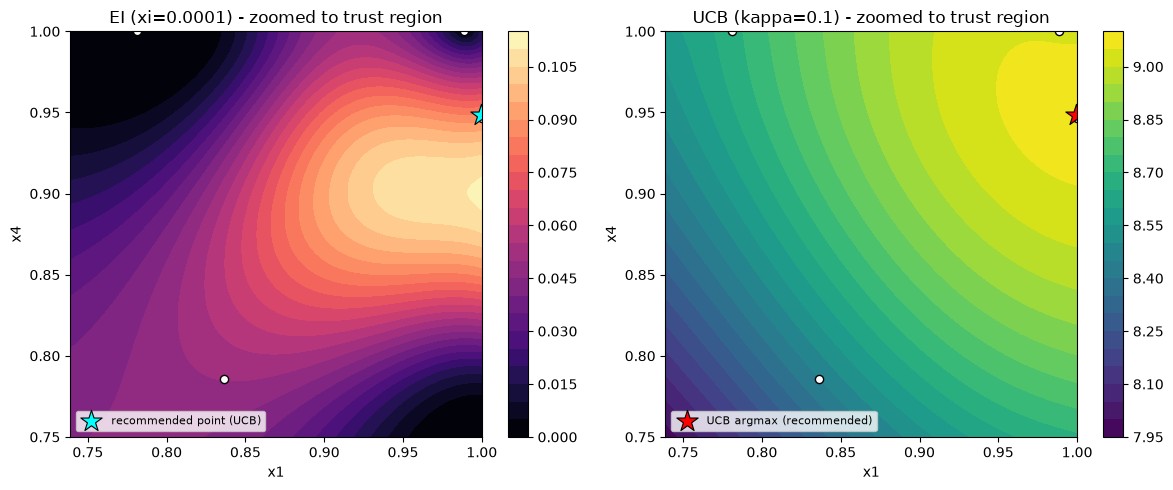

In [16]:
# =========================================================================
# Figure: trust-region EI/UCB surface around the incumbent (x1,x4 slice,
# since those are the two coordinates that have moved across rounds 2-4)
# =========================================================================
grid_n = 80
lo1, hi1 = trust_bounds[0]
lo4, hi4 = trust_bounds[3]
g1 = np.linspace(lo1, hi1, grid_n)
g4 = np.linspace(lo4, hi4, grid_n)
G1, G4 = np.meshgrid(g1, g4)

Xg = np.tile(best_x, (grid_n * grid_n, 1))
Xg[:, 0] = G1.ravel()
Xg[:, 3] = G4.ravel()
ei_g = expected_improvement(Xg, gp, f_best, xi).reshape(grid_n, grid_n)
ucb_g = ucb(Xg, gp, kappa).reshape(grid_n, grid_n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].contourf(G1, G4, ei_g, levels=25, cmap="magma")
axes[0].scatter(X[:, 0], X[:, 3], c="white", edgecolor="k", s=35)
axes[0].scatter(best_x[0], best_x[3], marker="*", c="cyan", s=260,
                edgecolor="k", linewidth=0.8, label="recommended point (UCB)")
axes[0].set_xlim(lo1, hi1); axes[0].set_ylim(lo4, hi4)
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x4")
axes[0].set_title(f"EI (xi={xi}) - zoomed to trust region")
plt.colorbar(im0, ax=axes[0]); axes[0].legend(fontsize=8, loc="lower left")

im1 = axes[1].contourf(G1, G4, ucb_g, levels=25, cmap="viridis")
axes[1].scatter(X[:, 0], X[:, 3], c="white", edgecolor="k", s=35)
axes[1].scatter(x_ucb_trust[0], x_ucb_trust[3], marker="*", c="red", s=260,
                edgecolor="k", linewidth=0.8, label="UCB argmax (recommended)")
axes[1].set_xlim(lo1, hi1); axes[1].set_ylim(lo4, hi4)
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x4")
axes[1].set_title(f"UCB (kappa={kappa}) - zoomed to trust region")
plt.colorbar(im1, ax=axes[1]); axes[1].legend(fontsize=8, loc="lower left")

plt.tight_layout()